# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Muhammad Hamdi Hakim
- **Email:** hamdimuhammad043@gmail.com
- **ID Dicoding:** DS001B6Y1173

## Menentukan Pertanyaan Bisnis

Analisis dibatasi pada pesanan berstatus `delivered` dengan tanggal pembelian **Januari 2017 – Agustus 2018**. Data 2016 sangat sedikit (hanya ratusan pesanan) dan data setelah Agustus 2018 tidak lengkap, sehingga keduanya dikeluarkan agar perbandingan antarbulan adil. Seluruh nilai uang dalam Real Brasil (R$), dan *revenue* dihitung dari `price` (tidak termasuk ongkos kirim).

1. **Kategori produk apa saja yang menghasilkan total revenue tertinggi dan terendah (10 teratas dan 10 terbawah) selama Januari 2017 – Agustus 2018?** *(Hasilnya menjadi dasar prioritas stok dan promosi.)*
2. **Bagaimana tren jumlah pesanan dan total revenue per bulan selama Januari 2017 – Agustus 2018, dan pada bulan apa terjadi puncaknya?** *(Hasilnya menjadi dasar penjadwalan kampanye dan kesiapan kapasitas.)*
3. **State mana yang memiliki rata-rata review score terendah dan persentase pesanan terlambat tertinggi selama Januari 2017 – Agustus 2018?** *(Hasilnya menjadi dasar perbaikan logistik di wilayah bermasalah.)*

**Analisis lanjutan (tanpa machine learning):** RFM Analysis untuk segmentasi pelanggan, Geospatial Analysis untuk memetakan performa pengiriman, serta Binning untuk mengelompokkan keterlambatan pengiriman.

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

HIGHLIGHT = "#1f6fb2"   # warna sorotan
MUTED = "#c9ced6"       # warna netral
ALERT = "#d1495b"       # warna peringatan

## Data Wrangling

### Gathering Data
Dataset terdiri dari 8 tabel CSV yang saling berelasi (pesanan, item pesanan, pelanggan, produk, ulasan, pembayaran, penjual, dan geolokasi). Tabel pembayaran dan penjual dimuat untuk kelengkapan, tetapi tidak dipakai menjawab pertanyaan bisnis.

In [2]:
DATA = "data/"
orders_df = pd.read_csv(DATA + "orders_dataset.csv")
items_df = pd.read_csv(DATA + "order_items_dataset.csv")
customers_df = pd.read_csv(DATA + "customers_dataset.csv")
products_df = pd.read_csv(DATA + "products_dataset.csv")
category_df = pd.read_csv(DATA + "product_category_name_translation.csv")
reviews_df = pd.read_csv(DATA + "order_reviews_dataset.csv")
payments_df = pd.read_csv(DATA + "order_payments_dataset.csv")
sellers_df = pd.read_csv(DATA + "sellers_dataset.csv")
geo_df = pd.read_csv(DATA + "geolocation_dataset.csv")

tables = {"orders": orders_df, "order_items": items_df, "customers": customers_df,
          "products": products_df, "category_translation": category_df,
          "order_reviews": reviews_df, "order_payments": payments_df,
          "sellers": sellers_df, "geolocation": geo_df}
pd.DataFrame({name: df.shape for name, df in tables.items()}, index=["baris", "kolom"]).T

,baris,kolom
orders,99441,8
order_items,112650,7
customers,99441,5
products,32951,9
category_translation,71,2
order_reviews,99224,7
order_payments,103886,5
sellers,3095,4
geolocation,1000163,5


In [3]:
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


**Insight:**
- Terdapat 8 tabel dengan total ±1,9 juta baris. Tabel `geolocation` paling besar (±1 juta baris), sedangkan tabel lain berkisar 3 ribu – 112 ribu baris.
- `orders` menjadi tabel pusat; `order_items`, `reviews`, dan `customers` dihubungkan lewat `order_id` / `customer_id`, sedangkan `products` dihubungkan lewat `product_id`.

### Assessing Data

In [4]:
for name in ["orders", "order_items", "customers", "products", "order_reviews", "geolocation"]:
    df = tables[name]
    print(f"=== {name} ===")
    print("Missing value:", df.isna().sum()[lambda s: s > 0].to_dict())
    print("Duplikat baris:", df.duplicated().sum())
    print()

=== orders ===
Missing value: {'order_approved_at': 160, 'order_delivered_carrier_date': 1783, 'order_delivered_customer_date': 2965}
Duplikat baris: 0

=== order_items ===
Missing value: {}
Duplikat baris: 0

=== customers ===
Missing value: {}
Duplikat baris: 0

=== products ===
Missing value: {'product_category_name': 610, 'product_name_lenght': 610, 'product_description_lenght': 610, 'product_photos_qty': 610, 'product_weight_g': 2, 'product_length_cm': 2, 'product_height_cm': 2, 'product_width_cm': 2}
Duplikat baris: 0

=== order_reviews ===
Missing value: {'review_comment_title': 87656, 'review_comment_message': 58247}
Duplikat baris: 0

=== geolocation ===
Missing value: {}
Duplikat baris: 261831



In [5]:
# Tipe data kolom tanggal pada orders
orders_df.dtypes

order_id                         object
customer_id                      object
order_status                     object
order_purchase_timestamp         object
order_approved_at                object
order_delivered_carrier_date     object
order_delivered_customer_date    object
order_estimated_delivery_date    object
dtype: object

In [6]:
# Status pesanan dan rentang waktu pembelian
print(orders_df["order_status"].value_counts())
print()
print("Rentang pembelian:", orders_df["order_purchase_timestamp"].min(), "s.d.", orders_df["order_purchase_timestamp"].max())
volume = (pd.to_datetime(orders_df["order_purchase_timestamp"]).dt.to_period("M").value_counts().sort_index())
volume.head(6)

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Rentang pembelian: 2016-09-04 21:15:19 s.d. 2018-10-17 17:30:18


order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
Freq: M, Name: count, dtype: int64

In [7]:
# Pesanan berstatus delivered tetapi tanggal tiba di pelanggan kosong (data tidak konsisten)
delivered = orders_df[orders_df["order_status"] == "delivered"]
print("delivered tanpa order_delivered_customer_date:", delivered["order_delivered_customer_date"].isna().sum())

# Review ganda untuk satu pesanan
print("Pesanan dengan lebih dari 1 review:", (reviews_df["order_id"].value_counts() > 1).sum())

# Kategori produk kosong dan kategori tanpa terjemahan
print("Produk tanpa kategori:", products_df["product_category_name"].isna().sum())
missing_tr = set(products_df["product_category_name"].dropna()) - set(category_df["product_category_name"])
print("Kategori tanpa terjemahan Inggris:", missing_tr)

# Pelanggan: customer_id vs customer_unique_id
print("customer_id unik:", customers_df["customer_id"].nunique(), "| customer_unique_id unik:", customers_df["customer_unique_id"].nunique())

delivered tanpa order_delivered_customer_date: 8
Pesanan dengan lebih dari 1 review: 547
Produk tanpa kategori: 610
Kategori tanpa terjemahan Inggris: {'portateis_cozinha_e_preparadores_de_alimentos', 'pc_gamer'}
customer_id unik: 99441 | customer_unique_id unik: 96096


In [8]:
# Outlier harga dan ongkir
print(items_df[["price", "freight_value"]].describe().round(2))
print("Item dengan price > 1000:", (items_df["price"] > 1000).sum())
print("Item dengan ongkir > harga:", (items_df["freight_value"] > items_df["price"]).sum())

# Geolokasi: duplikat dan koordinat di luar Brasil
outside = ~(geo_df["geolocation_lat"].between(-34, 6) & geo_df["geolocation_lng"].between(-74, -34))
print("Geolokasi duplikat:", geo_df.duplicated().sum(), "| koordinat di luar Brasil:", outside.sum())
print("Zip prefix unik di geolokasi:", geo_df["geolocation_zip_code_prefix"].nunique())

           price  freight_value
count  112650.00      112650.00
mean      120.65          19.99
std       183.63          15.81
min         0.85           0.00
25%        39.90          13.08
50%        74.99          16.26
75%       134.90          21.15
max      6735.00         409.68
Item dengan price > 1000: 844
Item dengan ongkir > harga: 4124
Geolokasi duplikat: 261831 | koordinat di luar Brasil: 42
Zip prefix unik di geolokasi: 19015


**Insight (masalah kualitas data yang ditemukan) beserta tindakan pada tahap Cleaning:**

| # | Tabel | Masalah | Jenis | Tindakan |
|---|---|---|---|---|
| 1 | orders | Kolom tanggal bertipe `object` (string) | Invalid value | Ubah ke `datetime` |
| 2 | orders | Missing value pada `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date`; 8 pesanan `delivered` tanpa tanggal tiba | Missing & inconsistent value | Hanya simpan pesanan `delivered` yang punya tanggal tiba (dibutuhkan untuk menghitung keterlambatan) |
| 3 | orders | Data 2016 hanya ratusan pesanan dan data akhir 2018 tidak lengkap; status pesanan beragam (canceled, shipped, dsb.) | Inaccurate/skewed value | Batasi ke `delivered` dan Januari 2017 – Agustus 2018 |
| 4 | order_reviews | 547 pesanan memiliki lebih dari satu review | Duplicate data | Ambil review terakhir (berdasarkan `review_answer_timestamp`) per pesanan |
| 5 | products | 610 produk tanpa kategori; 2 kategori tidak punya terjemahan Inggris | Missing value | Isi `unknown` dan lengkapi terjemahan secara manual |
| 6 | geolocation | 261.831 baris duplikat, 42 koordinat di luar Brasil, banyak koordinat untuk satu zip prefix | Duplicate & invalid value | Hapus duplikat dan koordinat tidak valid, lalu rata-ratakan per zip prefix |
| 7 | order_items | Harga ekstrem (maks. R$ 6.735; 844 item > R$ 1.000) | Outlier | **Dipertahankan**: terlihat sebagai produk mahal yang wajar (bukan salah input), dan menghapusnya akan mengurangi revenue sebenarnya |
| 8 | customers | `customer_id` (99.441) berbeda dengan `customer_unique_id` (96.096) | Inconsistent identifier | Gunakan `customer_unique_id` sebagai identitas pelanggan untuk analisis RFM |

### Cleaning Data

**1) Pesanan: ubah tipe tanggal, filter status dan periode, serta hitung keterlambatan**

In [9]:
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
for col in date_cols:
    orders_df[col] = pd.to_datetime(orders_df[col])

clean_orders = orders_df[(orders_df["order_status"] == "delivered") & orders_df["order_delivered_customer_date"].notna()]
clean_orders = clean_orders[(clean_orders["order_purchase_timestamp"] >= "2017-01-01") &
                            (clean_orders["order_purchase_timestamp"] < "2018-09-01")].copy()

# keterlambatan: selisih tanggal tiba dengan estimasi (hari). Positif = terlambat
clean_orders["delay_days"] = (clean_orders["order_delivered_customer_date"] - clean_orders["order_estimated_delivery_date"]).dt.total_seconds() / 86400
clean_orders["is_late"] = clean_orders["delay_days"] > 0
clean_orders["delivery_days"] = (clean_orders["order_delivered_customer_date"] - clean_orders["order_purchase_timestamp"]).dt.total_seconds() / 86400

print("Jumlah pesanan setelah dibersihkan:", len(clean_orders))
clean_orders[["order_purchase_timestamp", "order_delivered_customer_date", "delay_days", "is_late"]].head()

Jumlah pesanan setelah dibersihkan: 96203


,order_purchase_timestamp,order_delivered_customer_date,delay_days,is_late
0,2017-10-02 10:56:33,2017-10-10 21:25:13,-7.107488,False
1,2018-07-24 20:41:37,2018-08-07 15:27:45,-5.355729,False
2,2018-08-08 08:38:49,2018-08-17 18:06:29,-17.245498,False
3,2017-11-18 19:28:06,2017-12-02 00:28:42,-12.980069,False
4,2018-02-13 21:18:39,2018-02-16 18:17:02,-9.238171,False


**2) Review: satu review terakhir per pesanan**

In [10]:
reviews_df["review_answer_timestamp"] = pd.to_datetime(reviews_df["review_answer_timestamp"])
clean_reviews = (reviews_df.sort_values("review_answer_timestamp")
                 .drop_duplicates("order_id", keep="last")[["order_id", "review_score"]])
print("Pesanan dengan review ganda setelah dibersihkan:", (clean_reviews["order_id"].value_counts() > 1).sum())

Pesanan dengan review ganda setelah dibersihkan: 0


**3) Produk: tangani kategori kosong dan lengkapi terjemahan**

In [11]:
products_df["product_category_name"] = products_df["product_category_name"].fillna("unknown")
extra_translation = pd.DataFrame({
    "product_category_name": ["portateis_cozinha_e_preparadores_de_alimentos", "pc_gamer", "unknown"],
    "product_category_name_english": ["portable_kitchen_food_preparers", "pc_gamer", "unknown"]})
category_full = pd.concat([category_df, extra_translation], ignore_index=True)
clean_products = products_df.merge(category_full, on="product_category_name", how="left")
print("Kategori tanpa terjemahan:", clean_products["product_category_name_english"].isna().sum())

Kategori tanpa terjemahan: 0


**4) Geolokasi: hapus duplikat dan koordinat tidak valid, lalu agregasi per zip prefix**

In [12]:
geo_clean = geo_df.drop_duplicates()
in_brazil = geo_clean["geolocation_lat"].between(-34, 6) & geo_clean["geolocation_lng"].between(-74, -34)
geo_clean = geo_clean[in_brazil]
geo_zip = (geo_clean.groupby("geolocation_zip_code_prefix", as_index=False)
           .agg(lat=("geolocation_lat", "mean"), lng=("geolocation_lng", "mean")))
print(f"Geolokasi: {len(geo_df):,} baris -> {len(geo_zip):,} baris (satu baris per zip prefix)")

Geolokasi: 1,000,163 baris -> 19,010 baris (satu baris per zip prefix)


**5) Gabungkan seluruh tabel menjadi satu dataset utama (level item pesanan)**

In [13]:
main_df = (items_df
    .merge(clean_orders[["order_id", "customer_id", "order_purchase_timestamp", "delay_days", "is_late", "delivery_days"]], on="order_id")
    .merge(customers_df, on="customer_id")
    .merge(clean_products[["product_id", "product_category_name_english"]], on="product_id", how="left")
    .merge(clean_reviews, on="order_id", how="left")
    .merge(geo_zip, left_on="customer_zip_code_prefix", right_on="geolocation_zip_code_prefix", how="left")
    .drop(columns=["geolocation_zip_code_prefix"]))
main_df["month"] = main_df["order_purchase_timestamp"].dt.to_period("M").dt.to_timestamp()

print("Bentuk dataset utama:", main_df.shape)
print("Jumlah pesanan unik:", main_df["order_id"].nunique())
print("Missing value tersisa:", main_df.isna().sum()[lambda s: s > 0].to_dict())
main_df.head()

Bentuk dataset utama: (109872, 21)
Jumlah pesanan unik: 96203
Missing value tersisa: {'review_score': 823, 'lat': 289, 'lng': 289}


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_purchase_timestamp,delay_days,is_late,delivery_days,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,product_category_name_english,review_score,lat,lng,month
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,2017-09-13 08:59:02,-8.011250,False,7.614421,871766c5855e863f6eccc05f988b23cb,28013,campos dos goytacazes,RJ,cool_stuff,5.0,-21.763186,-41.310265,2017-09-01
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,2017-04-26 10:53:06,-2.330278,False,16.216181,eb28e67c4c0b83846050ddfb8a35d051,15775,santa fe do sul,SP,pet_shop,4.0,-20.222506,-50.898951,2017-04-01
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,2018-01-14 14:33:31,-13.444954,False,7.948437,3818d81c6709e39d06b2738a8d3a2474,35661,para de minas,MG,furniture_decor,5.0,-19.869998,-44.593059,2018-01-01
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,2018-08-08 10:00:35,-5.435660,False,6.147269,af861d436cfc08b2c2ddefd0ba074622,12952,atibaia,SP,perfumery,4.0,-23.105968,-46.590277,2018-08-01
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,2017-02-04 13:57:51,-15.303808,False,25.114352,64b576fb70d441e8f1b2d7d446e483c5,13226,varzea paulista,SP,garden_tools,5.0,-23.243402,-46.827614,2017-02-01


**Insight:**
- Setelah pembersihan terdapat **96.203 pesanan** (109.872 item) pada Januari 2017 – Agustus 2018.
- Tabel geolokasi menyusut dari ±1 juta baris menjadi ±19 ribu baris (satu titik per zip prefix) sehingga proses join jauh lebih ringan.
- Missing value tersisa hanya pada `review_score` (823 item, pesanan tanpa review) dan koordinat (289 item, zip prefix pelanggan tidak ada di tabel geolokasi). Keduanya tidak dihapus karena tidak memengaruhi pertanyaan lain, dan baris tersebut diabaikan otomatis saat rata-rata atau peta dihitung.

**Ekspor data utama untuk dashboard** (kolom dipilih seperlunya agar file kecil dan dashboard cepat).

In [14]:
dashboard_cols = ["order_id", "customer_unique_id", "order_purchase_timestamp", "product_category_name_english",
                  "price", "freight_value", "customer_state", "review_score", "is_late", "delay_days", "lat", "lng"]
export_df = main_df[dashboard_cols].copy()
export_df["lat"] = export_df["lat"].round(3)
export_df["lng"] = export_df["lng"].round(3)
export_df["delay_days"] = export_df["delay_days"].round(2)
export_df.to_csv("dashboard/main_data.csv", index=False)

import os
print(f"dashboard/main_data.csv: {os.path.getsize('dashboard/main_data.csv') / 1e6:.1f} MB, {len(export_df):,} baris")

dashboard/main_data.csv: 16.1 MB, 109,872 baris


## Exploratory Data Analysis (EDA)

### Ringkasan statistik

In [15]:
order_level = main_df.drop_duplicates("order_id")   # satu baris per pesanan (untuk review dan keterlambatan)
print("Item pesanan:")
print(main_df[["price", "freight_value"]].describe().round(2))
print()
print("Pesanan:")
print(order_level[["review_score", "delivery_days", "delay_days"]].describe().round(2))
print()
print(f"Persentase pesanan terlambat: {order_level['is_late'].mean() * 100:.2f}%")
print(f"Total revenue (price): R$ {main_df['price'].sum():,.0f}")

Item pesanan:
           price  freight_value
count  109872.00      109872.00
mean      119.96          19.95
std       182.35          15.70
min         0.85           0.00
25%        39.90          13.08
50%        74.90          16.26
75%       134.04          21.15
max      6735.00         409.68

Pesanan:
       review_score  delivery_days  delay_days
count      95560.00       96203.00    96203.00
mean           4.16          12.54      -11.11
std            1.28           9.53       10.09
min            1.00           0.53     -146.02
25%            4.00           6.76      -16.22
50%            5.00          10.21      -11.82
75%            5.00          15.68       -6.38
max            5.00         209.63      188.98

Persentase pesanan terlambat: 8.13%
Total revenue (price): R$ 13,179,778


### Pertanyaan 1: Revenue per kategori produk

In [16]:
category_revenue = (main_df.groupby("product_category_name_english")
                    .agg(revenue=("price", "sum"), items=("order_id", "count"), orders=("order_id", "nunique"))
                    .sort_values("revenue", ascending=False))
category_revenue["share_%"] = category_revenue["revenue"] / category_revenue["revenue"].sum() * 100
print("10 kategori dengan revenue tertinggi:")
print(category_revenue.head(10).round(1))
print()
print("10 kategori dengan revenue terendah:")
print(category_revenue.tail(10).round(1))
print()
print(f"Kontribusi 10 kategori teratas: {category_revenue.head(10)['share_%'].sum():.1f}% dari total revenue ({len(category_revenue)} kategori)")

10 kategori dengan revenue tertinggi:
                                 revenue  items  orders  share_%
product_category_name_english                                   
health_beauty                  1229557.5   9422    8610      9.3
watches_gifts                  1163187.9   5853    5489      8.8
bed_bath_table                 1022955.8  10945    9267      7.8
sports_leisure                  952661.4   8413    7512      7.2
computers_accessories           887944.6   7631    6517      6.7
furniture_decor                 706237.2   8095    6258      5.4
housewares                      614341.6   6783    5734      4.7
cool_stuff                      609158.0   3711    3552      4.6
auto                            577721.1   4131    3801      4.4
garden_tools                    469135.4   4263    3443      3.6

10 kategori dengan revenue terendah:
                               revenue  items  orders  share_%
product_category_name_english                                 
fashion_sport     

### Pertanyaan 2: Tren pesanan dan revenue bulanan

In [17]:
monthly = (main_df.groupby("month")
           .agg(orders=("order_id", "nunique"), revenue=("price", "sum")))
monthly["orders_mom_%"] = monthly["orders"].pct_change() * 100
monthly["revenue_mom_%"] = monthly["revenue"].pct_change() * 100
print(monthly.round(1))
print()
print("Bulan puncak pesanan :", monthly["orders"].idxmax().strftime("%B %Y"), "-", monthly["orders"].max(), "pesanan")
print("Bulan puncak revenue :", monthly["revenue"].idxmax().strftime("%B %Y"), f"- R$ {monthly['revenue'].max():,.0f}")

            orders   revenue  orders_mom_%  revenue_mom_%
month                                                    
2017-01-01     750  111798.4           NaN            NaN
2017-02-01    1653  234223.4         120.4          109.5
2017-03-01    2546  359198.8          54.0           53.4
2017-04-01    2303  340669.7          -9.5           -5.2
2017-05-01    3545  489159.2          53.9           43.6
2017-06-01    3135  421923.4         -11.6          -13.7
2017-07-01    3872  481604.5          23.5           14.1
2017-08-01    4193  554699.7           8.3           15.2
2017-09-01    4150  607399.7          -1.0            9.5
2017-10-01    4478  648247.6           7.9            6.7
2017-11-01    7288  987648.1          62.8           52.4
2017-12-01    5513  726033.2         -24.4          -26.5
2018-01-01    7069  924645.0          28.2           27.4
2018-02-01    6555  826437.1          -7.3          -10.6
2018-03-01    7003  953356.2           6.8           15.4
2018-04-01    

### Pertanyaan 3: Review score dan keterlambatan per state

In [18]:
state_perf = (order_level.groupby("customer_state")
              .agg(orders=("order_id", "count"), avg_review=("review_score", "mean"), late_pct=("is_late", "mean")))
state_perf["late_pct"] *= 100
# state dengan pesanan < 100 dikeluarkan dari peringkat karena sampel terlalu kecil
state_rank = state_perf[state_perf["orders"] >= 100]
print("State dikeluarkan karena < 100 pesanan:", sorted(state_perf.index.difference(state_rank.index)))
print()
print("5 state dengan review score terendah:")
print(state_rank.sort_values("avg_review").head(5).round(2))
print()
print("5 state dengan persentase terlambat tertinggi:")
print(state_rank.sort_values("late_pct", ascending=False).head(5).round(2))
print()
print("Rata-rata review pesanan tepat waktu vs terlambat:")
print(order_level.groupby("is_late")["review_score"].mean().round(2))

State dikeluarkan karena < 100 pesanan: ['AC', 'AP', 'RR']

5 state dengan review score terendah:
                orders  avg_review  late_pct
customer_state                              
MA                 713        3.83     19.64
AL                 396        3.85     23.99
SE                 332        3.90     15.36
PA                 942        3.91     12.42
BA                3253        3.93     14.05

5 state dengan persentase terlambat tertinggi:
                orders  avg_review  late_pct
customer_state                              
AL                 396        3.85     23.99
MA                 713        3.83     19.64
PI                 475        3.99     16.00
CE                1273        3.94     15.40
SE                 332        3.90     15.36

Rata-rata review pesanan tepat waktu vs terlambat:
is_late
False    4.29
True     2.57
Name: review_score, dtype: float64


**Insight EDA:**
- Total revenue ±R$ 13,18 juta; harga rata-rata per item R$ 119,96 dengan median R$ 74,90 (distribusi condong ke kanan karena ada produk mahal).
- Sepuluh kategori teratas menyumbang sekitar **62,5%** revenue dari 74 kategori.
- Volume pesanan tumbuh dari 750 (Jan 2017) menjadi >6.000 per bulan sepanjang 2018, dengan lonjakan tajam pada November 2017.
- Pesanan terlambat hanya **8,13%**, tetapi review-nya jauh lebih rendah (2,57 vs 4,29 untuk yang tepat waktu).

## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori produk apa saja yang menghasilkan total revenue tertinggi dan terendah?

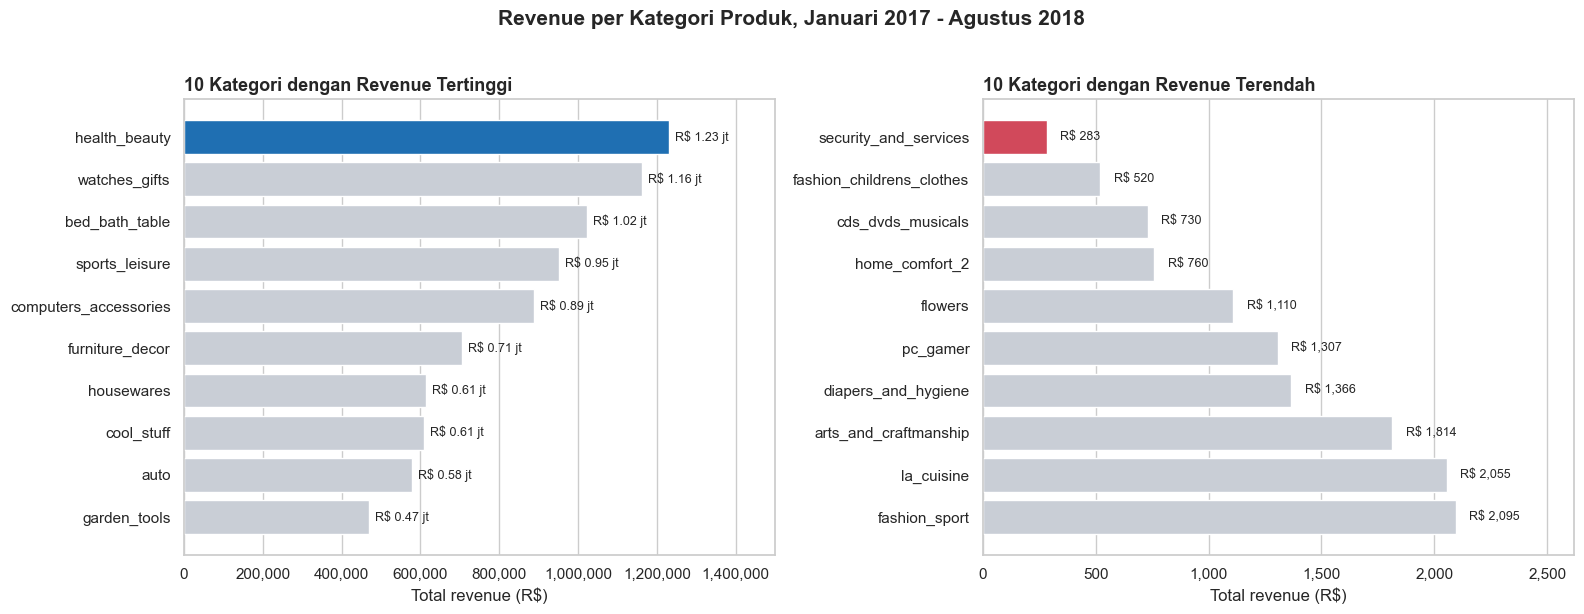

In [19]:
top10 = category_revenue.head(10)["revenue"].sort_values()
bottom10 = category_revenue.tail(10)["revenue"].sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

colors_top = [MUTED] * 9 + [HIGHLIGHT]          # sorot kategori nomor 1
axes[0].barh(top10.index, top10.values, color=colors_top)
axes[0].set_title("10 Kategori dengan Revenue Tertinggi", fontsize=13, loc="left", fontweight="bold")
for y, v in enumerate(top10.values):
    axes[0].text(v + 15000, y, f"R$ {v/1e6:.2f} jt", va="center", fontsize=9)
axes[0].set_xlim(0, top10.max() * 1.22)

colors_bottom = [MUTED] * 9 + [ALERT]            # sorot kategori terendah
axes[1].barh(bottom10.index, bottom10.values, color=colors_bottom)
axes[1].set_title("10 Kategori dengan Revenue Terendah", fontsize=13, loc="left", fontweight="bold")
for y, v in enumerate(bottom10.values):
    axes[1].text(v + 60, y, f"R$ {v:,.0f}", va="center", fontsize=9)
axes[1].set_xlim(0, bottom10.max() * 1.25)

for ax in axes:
    ax.set_xlabel("Total revenue (R$)")
    ax.set_ylabel("")
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))
    ax.grid(axis="y", visible=False)
fig.suptitle("Revenue per Kategori Produk, Januari 2017 - Agustus 2018", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

**Insight:**
- **health_beauty** (R$ 1,23 jt), **watches_gifts** (R$ 1,16 jt), dan **bed_bath_table** (R$ 1,02 jt) adalah tiga kategori dengan revenue tertinggi. Sepuluh kategori teratas menguasai 62,5% total revenue, sehingga pendapatan sangat terkonsentrasi.
- Kategori terendah seperti **security_and_services** (R$ 283) dan **fashion_childrens_clothes** (R$ 520) hampir tidak berkontribusi (< 0,01% revenue) dan umumnya berskala sangat kecil.

### Pertanyaan 2: Bagaimana tren pesanan dan revenue bulanan, dan kapan puncaknya?

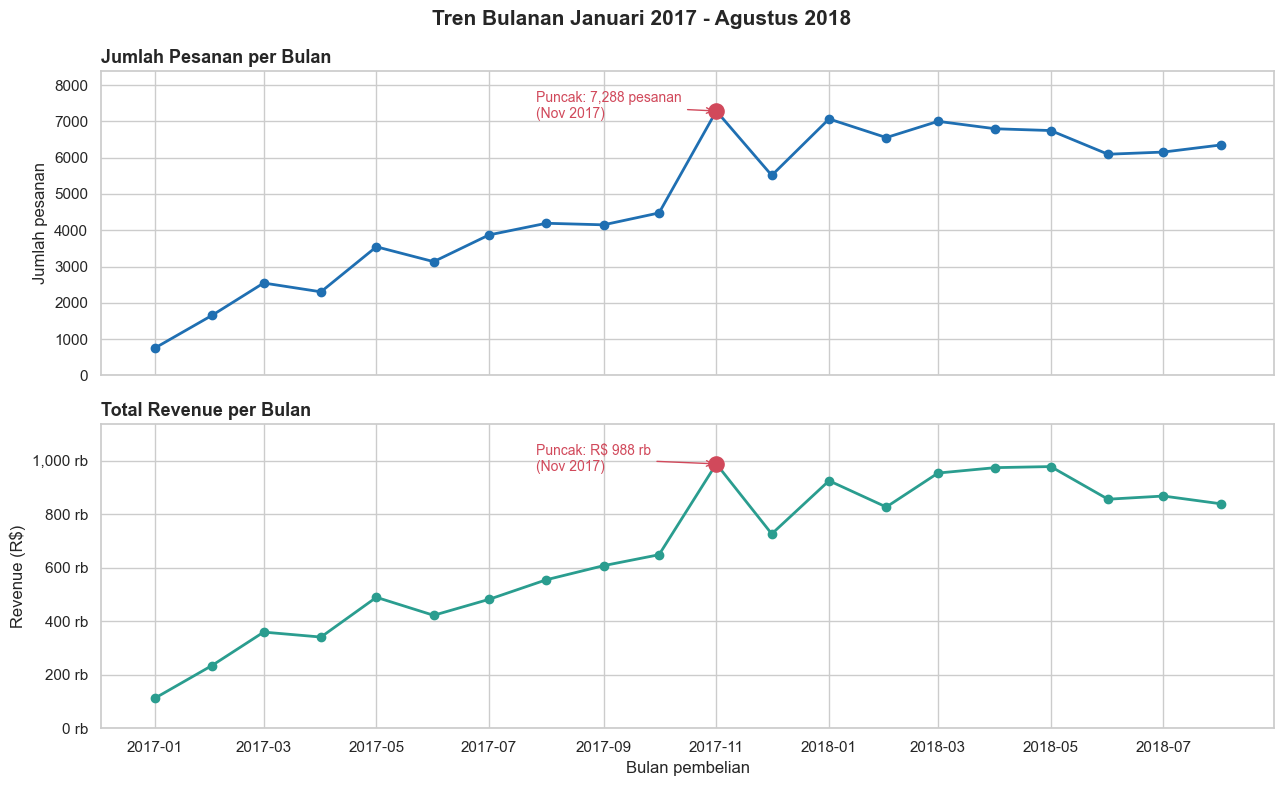

In [20]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

axes[0].plot(monthly.index, monthly["orders"], color=HIGHLIGHT, marker="o", linewidth=2)
peak_o = monthly["orders"].idxmax()
axes[0].scatter(peak_o, monthly.loc[peak_o, "orders"], color=ALERT, s=120, zorder=5)
axes[0].annotate(f"Puncak: {monthly.loc[peak_o, 'orders']:,} pesanan\n({peak_o.strftime('%b %Y')})",
                 (peak_o, monthly.loc[peak_o, "orders"]), xytext=(-130, -5), textcoords="offset points",
                 fontsize=10, color=ALERT, arrowprops=dict(arrowstyle="->", color=ALERT))
axes[0].set_title("Jumlah Pesanan per Bulan", fontsize=13, loc="left", fontweight="bold")
axes[0].set_ylabel("Jumlah pesanan")
axes[0].set_ylim(0, monthly["orders"].max() * 1.15)

axes[1].plot(monthly.index, monthly["revenue"], color="#2a9d8f", marker="o", linewidth=2)
peak_r = monthly["revenue"].idxmax()
axes[1].scatter(peak_r, monthly.loc[peak_r, "revenue"], color=ALERT, s=120, zorder=5)
axes[1].annotate(f"Puncak: R$ {monthly.loc[peak_r, 'revenue']/1e3:,.0f} rb\n({peak_r.strftime('%b %Y')})",
                 (peak_r, monthly.loc[peak_r, "revenue"]), xytext=(-130, -5), textcoords="offset points",
                 fontsize=10, color=ALERT, arrowprops=dict(arrowstyle="->", color=ALERT))
axes[1].set_title("Total Revenue per Bulan", fontsize=13, loc="left", fontweight="bold")
axes[1].set_ylabel("Revenue (R$)")
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e3:,.0f} rb"))
axes[1].set_ylim(0, monthly["revenue"].max() * 1.15)
axes[1].set_xlabel("Bulan pembelian")

fig.suptitle("Tren Bulanan Januari 2017 - Agustus 2018", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

**Insight:**
- Pesanan tumbuh dari 750 (Jan 2017) menjadi 6.351 (Agu 2018). Pertumbuhan paling cepat terjadi sepanjang 2017, lalu mendatar di kisaran 6.000 – 7.000 pesanan per bulan sejak Januari 2018.
- **November 2017 adalah puncak** pesanan (7.288, naik ±63% dari Oktober) sekaligus revenue (R$ 987.648). Lonjakan ini sangat mungkin terkait momentum diskon akhir tahun seperti Black Friday (hipotesis, belum diuji dengan data kampanye), dan langsung turun ±24% pada Desember 2017.
- Sejak puncak revenue April–Mei 2018, revenue cenderung turun tipis hingga Agustus 2018.

### Pertanyaan 3: State mana yang memiliki review score terendah dan persentase keterlambatan tertinggi?

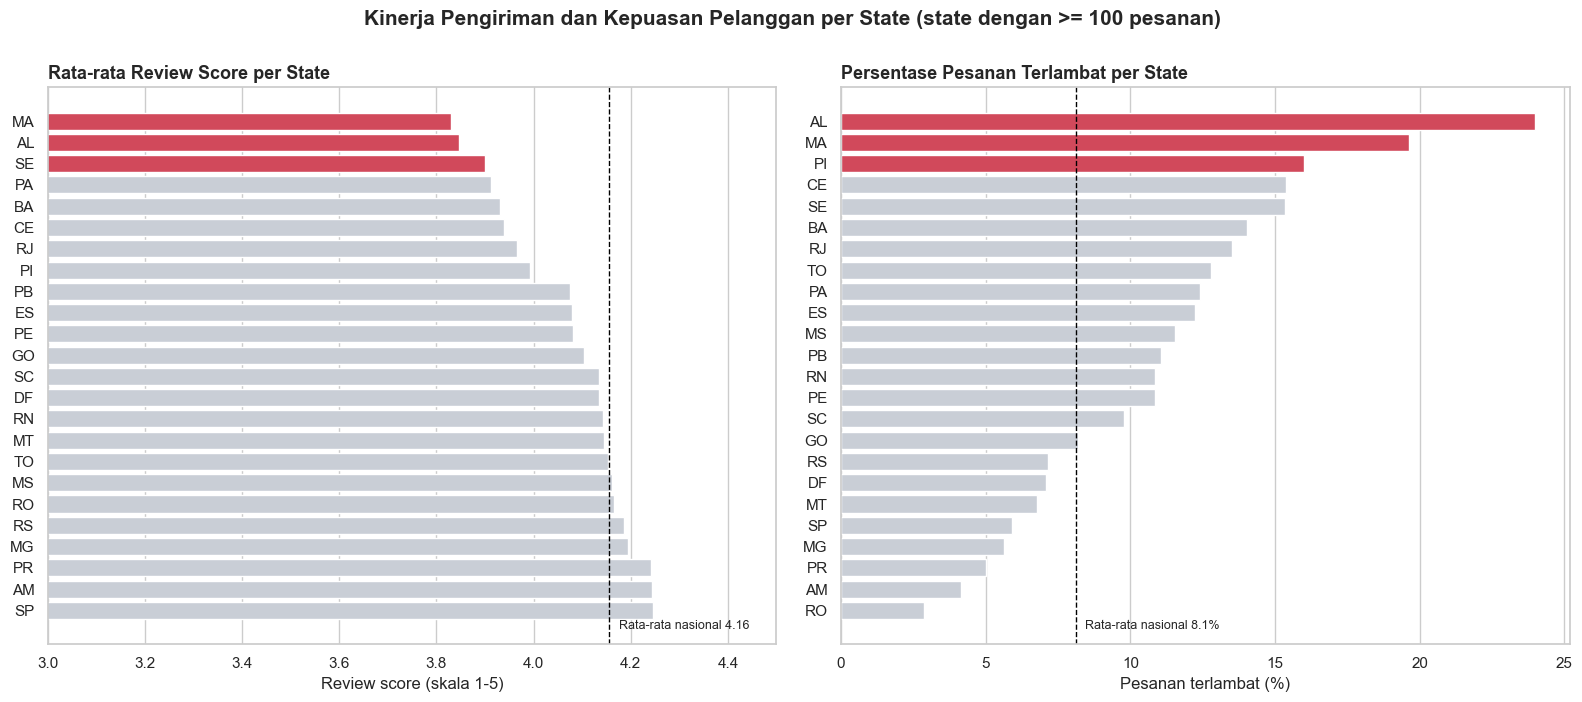

In [21]:
rank = state_rank.copy()
avg_all = order_level["review_score"].mean()
late_all = order_level["is_late"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

rv = rank.sort_values("avg_review", ascending=False)       # terendah berada di atas pada barh
rv_colors = [ALERT if v <= rv["avg_review"].nsmallest(3).max() else MUTED for v in rv["avg_review"]]
axes[0].barh(rv.index, rv["avg_review"], color=rv_colors)
axes[0].axvline(avg_all, color="black", linestyle="--", linewidth=1)
axes[0].text(avg_all + 0.02, -0.9, f"Rata-rata nasional {avg_all:.2f}", fontsize=9)
axes[0].set_title("Rata-rata Review Score per State", fontsize=13, loc="left", fontweight="bold")
axes[0].set_xlabel("Review score (skala 1-5)")
axes[0].set_xlim(3.0, 4.5)

lt = rank.sort_values("late_pct")
lt_colors = [ALERT if v >= lt["late_pct"].nlargest(3).min() else MUTED for v in lt["late_pct"]]
axes[1].barh(lt.index, lt["late_pct"], color=lt_colors)
axes[1].axvline(late_all, color="black", linestyle="--", linewidth=1)
axes[1].text(late_all + 0.3, -0.9, f"Rata-rata nasional {late_all:.1f}%", fontsize=9)
axes[1].set_title("Persentase Pesanan Terlambat per State", fontsize=13, loc="left", fontweight="bold")
axes[1].set_xlabel("Pesanan terlambat (%)")

for ax in axes:
    ax.set_ylabel("")
    ax.grid(axis="y", visible=False)
fig.suptitle("Kinerja Pengiriman dan Kepuasan Pelanggan per State (state dengan >= 100 pesanan)", fontsize=15, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

**Insight:**
- **MA (Maranhão)** dan **AL (Alagoas)** adalah dua state yang bermasalah di kedua metrik: review terendah (3,83 dan 3,85) sekaligus keterlambatan tertinggi (19,6% dan 24,0%, jauh di atas rata-rata nasional 8,1%). SE, PA, BA, PI, dan CE juga berada di bawah rata-rata review atau di atas rata-rata keterlambatan.
- State di Selatan dan Tenggara (SP, PR, MG, RS) memiliki review tertinggi (sekitar 4,19–4,25) dan keterlambatan rendah (sekitar 5–7%), sedangkan pesanan terlambat secara umum menurunkan review dari 4,29 menjadi 2,57. Artinya keterlambatan adalah pemicu utama ketidakpuasan.

## Analisis Lanjutan (Opsional)

### RFM Analysis
RFM mengelompokkan pelanggan berdasarkan perilaku belanja: **Recency** (hari sejak pembelian terakhir), **Frequency** (jumlah pesanan), dan **Monetary** (total belanja). Analisis memakai `customer_unique_id` karena `customer_id` berubah di setiap pesanan.

Karena ±97% pelanggan hanya membeli satu kali, skor frequency berbasis kuartil tidak informatif. Maka segmentasi dibuat dengan *manual grouping*: pelanggan dengan ≥ 2 pesanan disebut *Loyal*, sedangkan sisanya dibagi berdasarkan skor Recency (R) dan Monetary (M) berbasis kuartil.

In [22]:
snapshot = main_df["order_purchase_timestamp"].max() + pd.Timedelta(days=1)
rfm = (main_df.groupby("customer_unique_id")
       .agg(last_purchase=("order_purchase_timestamp", "max"),
            frequency=("order_id", "nunique"),
            monetary=("price", "sum")))
rfm["recency"] = (snapshot - rfm["last_purchase"]).dt.days

rfm["R_score"] = pd.qcut(rfm["recency"], 4, labels=[4, 3, 2, 1]).astype(int)   # recency kecil = skor tinggi
rfm["M_score"] = pd.qcut(rfm["monetary"], 4, labels=[1, 2, 3, 4]).astype(int)

def segment(row):
    if row["frequency"] >= 2:
        return "Loyal (>= 2 pesanan)"
    if row["R_score"] >= 3:
        return "Recent Big Spender" if row["M_score"] >= 3 else "Recent Small Spender"
    return "At Risk Big Spender" if row["M_score"] >= 3 else "Lost / Low Value"

rfm["segment"] = rfm.apply(segment, axis=1)
rfm_summary = (rfm.groupby("segment")
               .agg(pelanggan=("monetary", "size"), total_revenue=("monetary", "sum"),
                    avg_recency_hari=("recency", "mean"), avg_monetary=("monetary", "mean"))
               .sort_values("total_revenue", ascending=False))
rfm_summary["pelanggan_%"] = rfm_summary["pelanggan"] / rfm_summary["pelanggan"].sum() * 100
rfm_summary["revenue_%"] = rfm_summary["total_revenue"] / rfm_summary["total_revenue"].sum() * 100
print(f"Jumlah pelanggan unik: {len(rfm):,} | pelanggan dengan 1 pesanan: {(rfm['frequency'] == 1).mean() * 100:.1f}%")
rfm_summary.round(1)

Jumlah pelanggan unik: 93,096 | pelanggan dengan 1 pesanan: 97.0%


,pelanggan,total_revenue,avg_recency_hari,avg_monetary,pelanggan_%,revenue_%
segment,,,,,,
Recent Big Spender,22244,5151070.8,111.8,231.6,23.9,39.1
At Risk Big Spender,21965,5131472.4,362.5,233.6,23.6,38.9
Lost / Low Value,23318,1101038.2,362.0,47.2,25.0,8.4
Recent Small Spender,22780,1070841.5,111.2,47.0,24.5,8.1
Loyal (>= 2 pesanan),2789,725355.0,219.6,260.1,3.0,5.5


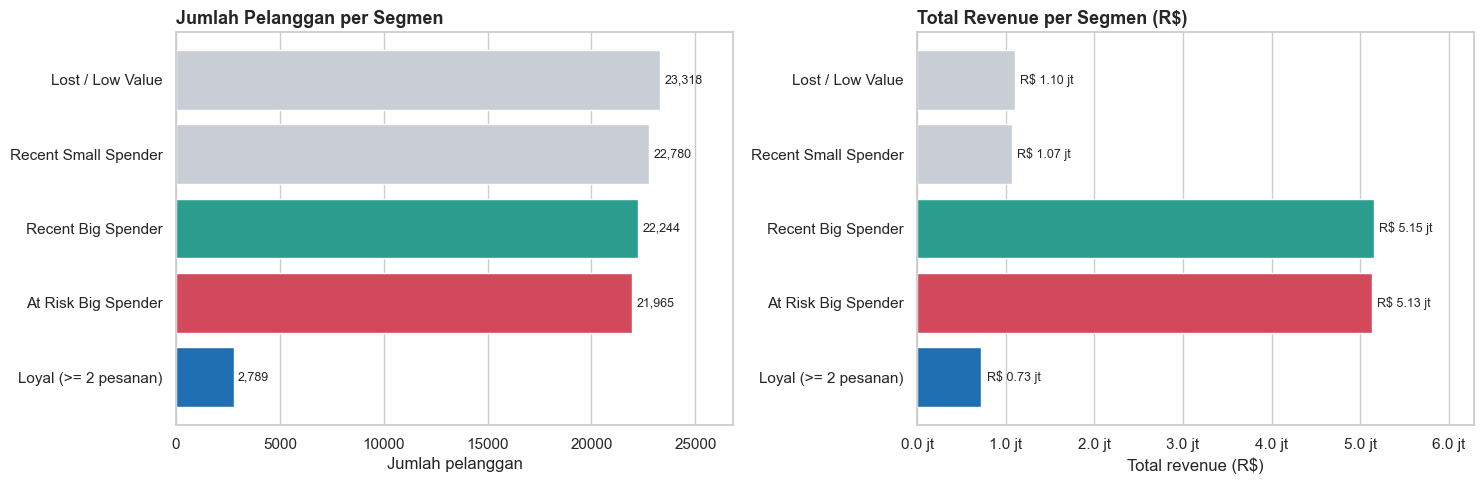

In [23]:
order = rfm_summary.sort_values("pelanggan", ascending=False).index
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
seg_colors = {"Loyal (>= 2 pesanan)": HIGHLIGHT, "Recent Big Spender": "#2a9d8f", "At Risk Big Spender": ALERT,
              "Recent Small Spender": MUTED, "Lost / Low Value": MUTED}

counts = rfm_summary.loc[order, "pelanggan"]
axes[0].barh(order, counts, color=[seg_colors[s] for s in order])
axes[0].set_title("Jumlah Pelanggan per Segmen", fontsize=13, loc="left", fontweight="bold")
axes[0].set_xlabel("Jumlah pelanggan")
axes[0].invert_yaxis()
for y, v in enumerate(counts):
    axes[0].text(v + 200, y, f"{v:,.0f}", va="center", fontsize=9)
axes[0].set_xlim(0, counts.max() * 1.15)

revs = rfm_summary.loc[order, "total_revenue"]
axes[1].barh(order, revs, color=[seg_colors[s] for s in order])
axes[1].set_title("Total Revenue per Segmen (R$)", fontsize=13, loc="left", fontweight="bold")
axes[1].set_xlabel("Total revenue (R$)")
axes[1].invert_yaxis()
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e6:.1f} jt"))
for y, v in enumerate(revs):
    axes[1].text(v + 60000, y, f"R$ {v/1e6:.2f} jt", va="center", fontsize=9)
axes[1].set_xlim(0, revs.max() * 1.22)
for ax in axes:
    ax.set_ylabel("")
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Insight RFM:**
- Hanya sekitar **3%** pelanggan yang pernah membeli lebih dari sekali (2.789 pelanggan *Loyal*), sehingga retensi menjadi tantangan terbesar.
- Segmen **At Risk Big Spender** (21.965 pelanggan, rata-rata sudah ±362 hari tidak membeli) menyimpan revenue historis R$ 5,13 juta, hampir sama dengan **Recent Big Spender** (R$ 5,15 juta). Segmen ini adalah target utama kampanye *win-back*.

### Geospatial Analysis
Peta ini memetakan keterlambatan pengiriman per state. Setiap titik adalah satu state (di titik rata-rata koordinat pelanggan), ukuran titik menunjukkan jumlah pesanan, dan warna menunjukkan persentase pesanan terlambat. Tujuannya melihat apakah masalah logistik membentuk pola wilayah.

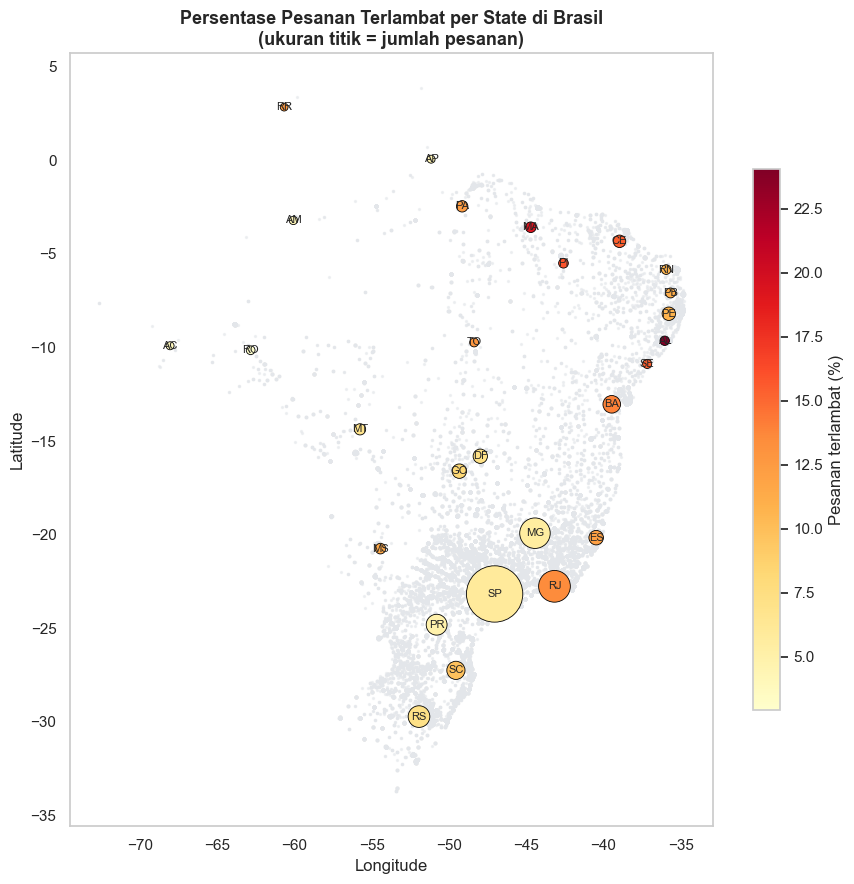

In [24]:
geo_state = (order_level.dropna(subset=["lat", "lng"])
             .groupby("customer_state")
             .agg(lat=("lat", "mean"), lng=("lng", "mean"), orders=("order_id", "count"), late_pct=("is_late", lambda s: s.mean() * 100)))

fig, ax = plt.subplots(figsize=(9, 9))
# latar: seluruh titik pelanggan sebagai kerangka peta Brasil
ax.scatter(order_level["lng"], order_level["lat"], s=2, color="#e3e6ea", alpha=0.5, zorder=1)
sc = ax.scatter(geo_state["lng"], geo_state["lat"], s=geo_state["orders"] / 25 + 30,
                c=geo_state["late_pct"], cmap="YlOrRd", edgecolor="black", linewidth=0.6, zorder=3)
for st, r in geo_state.iterrows():
    ax.annotate(st, (r["lng"], r["lat"]), fontsize=8, ha="center", va="center", zorder=4)
cbar = plt.colorbar(sc, ax=ax, shrink=0.7)
cbar.set_label("Pesanan terlambat (%)")
ax.set_title("Persentase Pesanan Terlambat per State di Brasil\n(ukuran titik = jumlah pesanan)", fontsize=13, fontweight="bold")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.grid(False)
plt.tight_layout()
plt.show()

**Insight Geospatial:** Keterlambatan paling tinggi terkonsentrasi di state-state kawasan **Timur Laut** Brasil (AL, MA, PI, CE, SE) yang jauh dari pusat penjualan di Tenggara (SP). Pola wilayah ini menunjukkan hambatan logistik jarak jauh, bukan masalah acak per pesanan.

### Binning: Kategori Keterlambatan Pengiriman
Binning mengelompokkan `delay_days` ke dalam interval untuk melihat bagaimana tingkat keterlambatan memengaruhi kepuasan pelanggan.

                           pesanan  avg_review  pesanan_%
delay_group                                              
Tepat waktu / lebih cepat    88381        4.29      91.87
Terlambat 1-3 hari            2660        3.77       2.76
Terlambat 4-7 hari            1819        2.32       1.89
Terlambat > 7 hari            3343        1.73       3.47


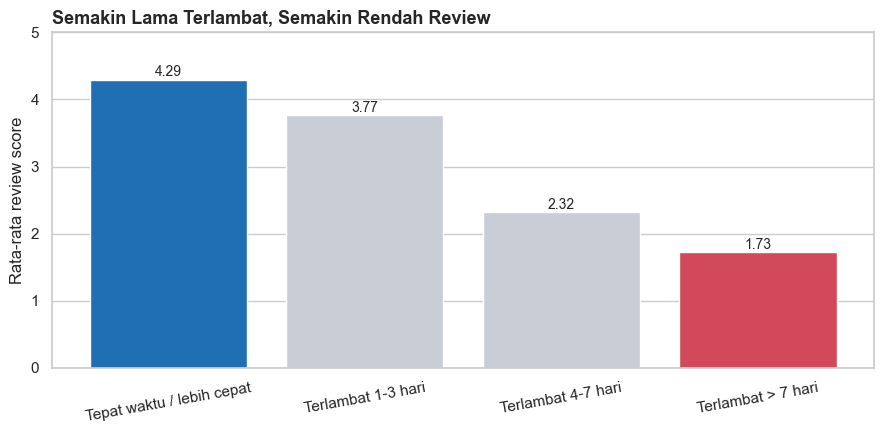

In [25]:
bins = [-np.inf, 0, 3, 7, np.inf]
labels = ["Tepat waktu / lebih cepat", "Terlambat 1-3 hari", "Terlambat 4-7 hari", "Terlambat > 7 hari"]
order_level = order_level.copy()
order_level["delay_group"] = pd.cut(order_level["delay_days"], bins=bins, labels=labels)

delay_summary = (order_level.groupby("delay_group", observed=True)
                 .agg(pesanan=("order_id", "count"), avg_review=("review_score", "mean")))
delay_summary["pesanan_%"] = delay_summary["pesanan"] / delay_summary["pesanan"].sum() * 100
print(delay_summary.round(2))

fig, ax = plt.subplots(figsize=(9, 4.5))
bar_colors = [HIGHLIGHT, MUTED, MUTED, ALERT]
ax.bar(delay_summary.index, delay_summary["avg_review"], color=bar_colors)
for i, v in enumerate(delay_summary["avg_review"]):
    ax.text(i, v + 0.05, f"{v:.2f}", ha="center", fontsize=10)
ax.set_ylim(0, 5)
ax.set_ylabel("Rata-rata review score")
ax.set_title("Semakin Lama Terlambat, Semakin Rendah Review", fontsize=13, fontweight="bold", loc="left")
ax.grid(axis="x", visible=False)
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

**Insight Binning:** Review turun tajam seiring lamanya keterlambatan. Pesanan tepat waktu rata-rata mendapat review 4,29, turun menjadi 3,77 untuk keterlambatan 1–3 hari, 2,32 untuk 4–7 hari, dan hanya 1,73 untuk keterlambatan > 7 hari. Pesanan yang terlambat > 7 hari memang hanya 3,5% dari total, tetapi dampaknya pada kepuasan sangat besar. Ini memperkuat temuan Pertanyaan 3 bahwa memperbaiki ketepatan pengiriman adalah tuas terbesar untuk kepuasan pelanggan.

## Conclusion

**Conclusion Pertanyaan 1 (kategori produk):**
Revenue terkonsentrasi pada segelintir kategori. **health_beauty** (R$ 1,23 jt), **watches_gifts** (R$ 1,16 jt), dan **bed_bath_table** (R$ 1,02 jt) memimpin, dan 10 kategori teratas menyumbang ±62,5% total revenue. Kategori terbawah (mis. security_and_services dan fashion_childrens_clothes) hampir tidak berkontribusi.

**Conclusion Pertanyaan 2 (tren bulanan):**
Pesanan tumbuh dari 750 (Jan 2017) ke ±6.000–7.000 per bulan pada 2018, dengan **puncak pada November 2017** (7.288 pesanan, R$ 987.648) lalu turun ±24% pada Desember. Pertumbuhan mendatar sepanjang 2018 dan revenue cenderung turun tipis sejak Mei 2018.

**Conclusion Pertanyaan 3 (kepuasan dan pengiriman per state):**
**MA dan AL** adalah state dengan review terendah (3,83 dan 3,85) sekaligus keterlambatan tertinggi (19,6% dan 24,0% vs rata-rata nasional 8,1%). Pesanan terlambat mendapat review rata-rata 2,57 dibanding 4,29 untuk yang tepat waktu, dan masalahnya terkonsentrasi di kawasan Timur Laut.

**Conclusion Analisis Lanjutan:**
Hanya ±3% pelanggan yang membeli ulang. Segmen *At Risk Big Spender* (±22 ribu pelanggan, R$ 5,13 jt) menjadi peluang retensi terbesar.

### Rekomendasi (Action Item)
1. **Prioritaskan stok, iklan, dan promosi pada kategori unggulan** (health_beauty, watches_gifts, bed_bath_table) dan evaluasi apakah kategori terbawah perlu dipertahankan atau digabung.
2. **Siapkan kampanye musiman dan kapasitas operasional sebelum November** (mis. stok, kurir, layanan pelanggan), lalu rancang promo pemicu pertumbuhan untuk mengatasi stagnasi sepanjang 2018.
3. **Perbaiki logistik di Timur Laut Brasil (AL, MA, PI, CE, SE)**: tambah gudang/mitra kurir regional atau perpanjang estimasi pengiriman agar lebih realistis, serta beri kompensasi proaktif (voucher) pada pesanan yang terlambat.
4. **Jalankan kampanye win-back untuk segmen At Risk Big Spender** (voucher personal) dan program loyalitas untuk mendorong pembelian kedua.